In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Data Preparation

In [3]:
df = pd.read_csv('./data/data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

# Validation Framework

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

# Encode & Train

In [5]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [6]:
y_train

array([0, 0, 1, ..., 1, 0, 1], shape=(4225,))

In [7]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

/home/rwin/Documents/github/ml-forge/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [8]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.801277501774308)

## Accuracy

$$
\mathbf{Accuracy} = \frac{\text{\# Correct predictions}}{\text{\# Total predictions}}
$$

In [9]:
acc = (y_val == churn_decision).sum() / len(y_val)
print(f"{(y_val == churn_decision).sum()} / {len(y_val)} = {acc}")

1129 / 1409 = 0.801277501774308


In [10]:
(y_val == churn_decision).mean()

np.float64(0.801277501774308)

In [11]:
accuracy_score(y_val, y_pred >= 0.5)

0.801277501774308

In [12]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print("Threshold: %.2f, Accuracy:%.3f" % (t, score))
    scores.append(score)

Threshold: 0.00, Accuracy:0.274
Threshold: 0.05, Accuracy:0.509
Threshold: 0.10, Accuracy:0.598
Threshold: 0.15, Accuracy:0.664
Threshold: 0.20, Accuracy:0.707
Threshold: 0.25, Accuracy:0.737
Threshold: 0.30, Accuracy:0.759
Threshold: 0.35, Accuracy:0.766
Threshold: 0.40, Accuracy:0.780
Threshold: 0.45, Accuracy:0.793
Threshold: 0.50, Accuracy:0.801
Threshold: 0.55, Accuracy:0.798
Threshold: 0.60, Accuracy:0.797
Threshold: 0.65, Accuracy:0.784
Threshold: 0.70, Accuracy:0.765
Threshold: 0.75, Accuracy:0.744
Threshold: 0.80, Accuracy:0.730
Threshold: 0.85, Accuracy:0.726
Threshold: 0.90, Accuracy:0.726
Threshold: 0.95, Accuracy:0.726
Threshold: 1.00, Accuracy:0.726


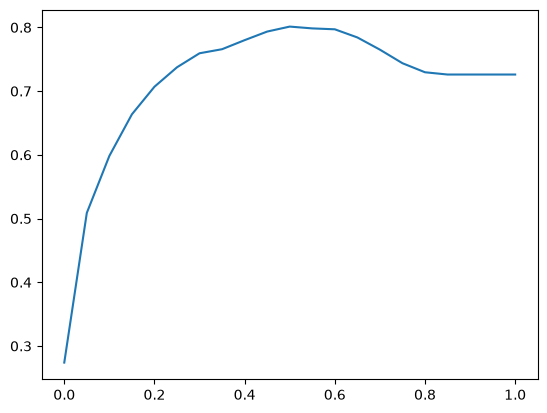

In [13]:
plt.plot(thresholds, scores)

### dummy model

$\text{Threshold} = 1.0 \rightarrow$ every customer is predicted as "no churn"

In [14]:
from collections import Counter

Counter(y_pred >= 1.0) 

Counter({np.False_: 1409})

- No True class (nobody is churning)

In [15]:
1 - y_val.mean()

np.float64(0.7260468417317246)

In [16]:
accuracy_score(y_val, y_pred >= 1.0) # checkout the plot

0.7260468417317246

Assuming `1` means churn and `0` means no churn, `y_val` contains the actual outcomes for the validation customers.  
Because the labels are zeros and ones, `y_val.mean()` is the fraction of customers who actually churned—the churn rate.  
For example, if `y_val.mean()` is `0.2`, then 20% churned and the remaining 80% did not.  
The expression `y_pred >= 1.0` converts each prediction into a class prediction: `True` for churn and `False` for no churn.  
If every value in `y_pred` is below `1.0`, this expression predicts no churn for every customer.  
`accuracy_score(y_val, y_pred >= 1.0)` then measures the fraction of those predictions that match the actual outcomes.  
For an always-no-churn prediction, it is correct exactly for the customers who did not churn.  
Therefore, that model’s accuracy is `1 - y_val.mean()`; this is not automatically the accuracy of your trained model.  
- A model that predicts **churn for everyone** has accuracy `y_val.mean()`.  
- A model that predicts **no churn for everyone** has accuracy `1 - y_val.mean()`.

### class imbalance
- there are many more instances of one class than of the other.

In [17]:
Counter(y_val)

Counter({np.int64(0): 1023, np.int64(1): 386})

In [18]:
print(accuracy_score(y_val, y_pred >= 0.5)) # our model accuracy
print(accuracy_score(y_val, y_pred >= 1.0)) # dummy model accuracy

0.801277501774308
0.7260468417317246


-  We can see that the improvement of the original model with respect to the dummy model is not as high as we would expect.

In [19]:
print(y_val.mean()) # churn rate
print(1-y_val.mean()) # non-churners fraction

0.2739531582682754
0.7260468417317246


With such an imbalance, a model can get a high accuracy by always predicting **the majority class**, while being completely useless for the **minority class**

For a model that predicts **no churn for everyone**. It correctly labels every actual non-churner, so its **specificity** (the fraction of actual non-churners it correctly identifies) is 100%. But it labels every actual churner as a non-churner, so it finds **none** of the churners: its **recall for churn** is 0%. That makes it a useful baseline for comparison, but useless for the goal of identifying customers likely to churn. A high overall accuracy can hide this failure, especially when most customers do not churn.

## Confusion table
- Confusion table is a way of measuring different types of errors and correct decisions that binary classifiers can make.

For churn prediction, each customer in the validation set falls into one of four categories, depending on what we predicted and what actually happened:

| Prediction | Actual | Name |
|------------|--------|------|
| Customer will churn (positive) | Churned | True Positive (TP) |
| Customer will churn (positive) | Did not churn | False Positive (FP) |
| Customer will not churn (negative) | Churned | False Negative (FN) |
| Customer will not churn (negative) | Did not churn | True Negative (TN) |


$$
g(\mathbf{x}_i) \longrightarrow
\begin{cases}
\underbrace{
g(\mathbf{x}_i)>t \longrightarrow \text{Churn (Positive)}
}_{\text{Prediction}}
\longrightarrow
\begin{cases}
\underbrace{\text{Customer Churned}}_{\text{Actual}}
\longrightarrow \text{True Positive}
\\
\underbrace{\text{Customer didn't Churn}}_{\text{Actual}}
\longrightarrow \text{False Positive}
\end{cases}
\\[1.5em]
\underbrace{
g(\mathbf{x}_i)<t \longrightarrow \text{No Churn (Negative)}
}_{\text{Prediction}}
\longrightarrow
\begin{cases}
\underbrace{\text{Customer Churned}}_{\text{Actual}}
\longrightarrow \text{False Negative}
\\
\underbrace{\text{Customer didn't Churn}}_{\text{Actual}}
\longrightarrow \text{True Negative}
\end{cases}
\end{cases}
$$

In [20]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [21]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [22]:
tp, tn, fp, fn, tp+tn+fp+fn

(np.int64(214), np.int64(915), np.int64(108), np.int64(172), np.int64(1409))

$$
\begin{array}{c|c|c}
& g(\mathbf{x}_i)<t \; (\text{Predicted Negative})
& g(\mathbf{x}_i)>t \; (\text{Predicted Positive}) \\
\hline
y=0 \; (\text{Actual Negative})
& \underbrace{915}_{TN}
& \underbrace{108}_{FP}
\\[1em]
y=1 \; (\text{Actual Positive})
& \underbrace{172}_{FN}
& \underbrace{214}_{TP}
\end{array}
$$

In [23]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[915, 108],
       [172, 214]])


|                | Predicted negative | Predicted positive |
|----------------|--------------------|--------------------|
| Actual negative | TN = 915          | FP = 108           |
| Actual positive | FN = 172          | TP = 214           |

In [24]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.08],
       [0.12, 0.15]])

- So $65\%$ of all customers are **true negatives**, $8\%$ **false positives**, $12\%$ **false negatives** and $15\%$ **true positives**.
- Accuracy is the sum of the diagonal - the correct decisions TN and TP - divided by the total. 

In [25]:
(915+214)/1409

0.801277501774308

## Precision
- Precision tells us the fraction of positive predictions that are correct

$P = \frac{TP}{TP + FP}$

In [26]:
p = tp / (tp + fp)
p

np.float64(0.6645962732919255)

we send a retention email to everyone **predicted to churn**. That is 214 + 108 = 322 people, but only 214 of them (the true positives) were actually going to leave. The other 108 - about a third of all emails - go to customers who were never at risk, and the discount we send them is wasted.



## Recall
- Recall measures the fraction of actual positive instances that we identified correctly.

$ R = \frac{TP}{TP + FN}$

In [27]:
r = tp / (tp + fn)
r

np.float64(0.5544041450777202)

214 + 172 = 386 customers **actually churned**, but our model flagged only 214 of them. For the remaining 172 - about 45% of all churners - we did nothing: no email, no discount, and the customer left.

actual churners | Flagged
----------------|--------
Person1|$\checkmark$     
Person2|$\checkmark$
Person3|$\checkmark$
Person4| X

$\text{Recall} = \frac{3}{4} = 75\%$

- accuracy said 80% correct, only 4 points above the dummy model. 
- Of the customers we alert, two thirds are real (**precision 66%**).
- we miss almost half of the customers who leave (**recall 55%**).



## ROC 
- Receiver Operating Characteristic
- Precision and recall look at the model at one fixed threshold. A ROC curve looks at all possible thresholds at once.

### TPR
- The true positive rate is the fraction of **actual positives** we identified correctly - same as recall
- This is the metric we want to maximize.

$$TPR = \frac{TP}{TP + FN}$$

### FPR
- The false positive rate is the fraction of **actual negatives** we got wrong
- This is the metric we want to minimize.

$$FPR = \frac{FP}{FP + TN}$$

for threshold = 0.5:

In [28]:
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)

In [29]:
tpr, fpr

(np.float64(0.5544041450777202), np.float64(0.10557184750733138))

we bother 10% of the customers who were never going to churn.

In [41]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (actual_positive & predict_positive).sum()
    tn = (actual_negative & predict_negative).sum()
    fp = (actual_negative & predict_positive).sum()
    fn = (actual_positive & predict_negative).sum()

    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [42]:
df_scores

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,386,1023,0,0,1.000000,1.000000
1,0.01,385,903,1,120,0.997409,0.882698
2,0.02,384,812,2,211,0.994819,0.793744
3,0.03,382,753,4,270,0.989637,0.736070
4,0.04,380,708,6,315,0.984456,0.692082
...,...,...,...,...,...,...,...
96,0.96,0,0,386,1023,0.000000,0.000000
97,0.97,0,0,386,1023,0.000000,0.000000
98,0.98,0,0,386,1023,0.000000,0.000000
99,0.99,0,0,386,1023,0.000000,0.000000


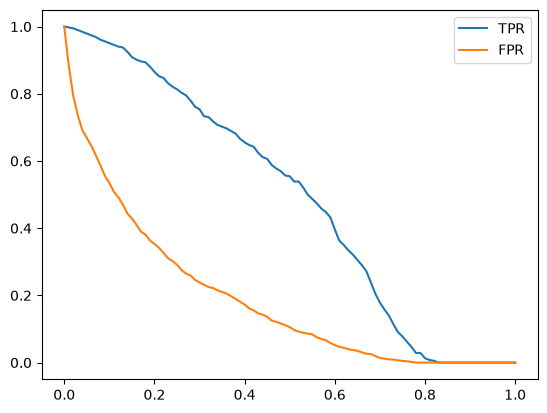

In [43]:
plt.plot(df_scores.threshold, df_scores.tpr, label='TPR')
plt.plot(df_scores.threshold, df_scores.fpr, label='FPR')
plt.legend()